# CDS 4003: Mobile Game In-App Purchases

## Stage 5: Model Selection and Development

**Models Implemented:** Random Forest and NLP (Tabular-to-Text TF-IDF + Logistic Regression)

## Model 2: Random Forest Classifier

In this section, we train a Random Forest classifier to predict `SpendingSegment` (`Minnow`, `Dolphin`, `Whale`) on the cleaned dataset (`mobile_game_players_eda_features.csv`).

* **Preprocessing & Leakage Prevention:** Excluded identifier, direct spending, date, and derived summary leakage columns (`UserID`, `InAppPurchaseAmount`, `InstallDate`, `LastPurchaseDate`, `InAppPurchaseAmountWasMissing`, `FirstPurchaseDaysAfterInstallWasMissing`, `AmountKnown`, `IAPForSummary`), dropped missing rows, split data `80/20` using `train_test_split` with `stratify=y` (`198,000` training and `49,500` test rows), and encoded categorical features with `OneHotEncoder(handle_unknown="ignore", sparse_output=False)` via `ColumnTransformer` (yielding `94` prepared features).
* **Handling Class Imbalance:** Applied `class_weight="balanced"` to account for the skewed `SpendingSegment` distribution (~84.17% `Minnow`, ~13.60% `Dolphin`, ~2.22% `Whale`) so minority segments (`Dolphin` and `Whale`) receive stronger weight during training.
* **Cross-Validation & Hyperparameter Tuning:** Evaluated a baseline model (`n_estimators=80`, `max_depth=15`, `min_samples_leaf=5`) using 3-fold `StratifiedKFold` cross-validation (`f1_macro`), then tuned hyperparameters with `RandomizedSearchCV` (`n_iter=6`, `scoring="f1_macro"`), selecting `{'n_estimators': 120, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 15, 'criterion': 'entropy'}` with a best CV Macro-F1 of `0.6924`.
* **Evaluation & Feature Importance:** Evaluated baseline vs. tuned performance on the held-out test set (`Accuracy`, `Balanced Accuracy`, `Macro-F1`, `classification_report`, and `confusion_matrix`), achieving a tuned test `Accuracy` of `0.8116`, `Balanced Accuracy` of `0.7823`, `Macro-F1` of `0.6872`, and `Whale` recall of `0.8336`, while visualizing top feature importances (`AdsPerActiveDay`, `AdsWatched30d`, `EngagementActionsPerActiveDay`, `AdViewBand`, `PurchaseCount30d`, `PurchasesPerActiveDay`).

In [13]:
#Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, RandomizedSearchCV
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

In [14]:
# 1. Load Data, Preprocess & Prevent Leakage
df = pd.read_csv("mobile_game_players_eda_features.csv")

# Drop IDs, direct spending amount (target leakage), and date/derived summary columns
drop_cols = [
    "UserID",
    "InAppPurchaseAmount",
    "InstallDate",
    "LastPurchaseDate",
    "InAppPurchaseAmountWasMissing",
    "FirstPurchaseDaysAfterInstallWasMissing",
    "AmountKnown",
    "IAPForSummary",
]
df_model = df.drop(columns=[c for c in drop_cols if c in df.columns]).dropna().copy()

target_col = "SpendingSegment"
X = df_model.drop(columns=[target_col])
y = df_model[target_col]

categorical_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
numeric_cols = X.select_dtypes(include=[np.number]).columns.tolist()

In [18]:
# 2. Train-Test Split (80/20 Stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

In [19]:
# Transform once outside CV/search to avoid repeating encoding overhead (Too avoid very long processing time)
preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numeric_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_cols),
    ]
)

X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()

print(f"Prepared shapes -> Train: {X_train_prep.shape}, Test: {X_test_prep.shape}")

Prepared shapes -> Train: (198000, 94), Test: (49500, 94)


In [28]:
# 3. Baseline Random Forest + Cross-Validation
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# Use max_depth cap and balanced class weights for imbalanced target
rf_baseline = RandomForestClassifier(
    n_estimators=80,
    max_depth=15,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=2,
)

cv_scores = cross_val_score(rf_baseline, X_train_prep, y_train, cv=cv, scoring="f1_macro", n_jobs=2)
print(f"Baseline RF 3-Fold CV Macro-F1: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")

rf_baseline.fit(X_train_prep, y_train)
y_pred_base = rf_baseline.predict(X_test_prep)

print("Baseline Random Forest (Test Set)")
print(f"Accuracy          : {accuracy_score(y_test, y_pred_base):.4f}")
print(f"Balanced Accuracy : {balanced_accuracy_score(y_test, y_pred_base):.4f}")
print(f"Macro-F1          : {f1_score(y_test, y_pred_base, average='macro'):.4f}")

Baseline RF 3-Fold CV Macro-F1: 0.6819 (+/- 0.0039)
Baseline Random Forest (Test Set)
Accuracy          : 0.8015
Balanced Accuracy : 0.7824
Macro-F1          : 0.6785


In [21]:
# 4. Fast Hyperparameter Tuning (RandomizedSearchCV)
param_distributions = {
    "n_estimators": [80, 120],
    "max_depth": [10, 15, 20],
    "min_samples_split": [5, 10],
    "min_samples_leaf": [2, 5, 10],
    "max_features": ["sqrt", "log2"],
    "criterion": ["gini", "entropy"],
}

rf_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(
        class_weight="balanced",
        random_state=42,
        n_jobs=1,  # Keep inner jobs=1 while outer search parallelizes across candidates/folds
    ),
    param_distributions=param_distributions,
    n_iter=6,               # Kept small for fast runtime on ~247.5k rows
    scoring="f1_macro",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=2,
)

rf_search.fit(X_train_prep, y_train)
best_rf = rf_search.best_estimator_

print(f"Best CV Macro-F1: {rf_search.best_score_:.4f}")
print("Best Hyperparameters:", rf_search.best_params_)

Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best CV Macro-F1: 0.6924
Best Hyperparameters: {'n_estimators': 120, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 15, 'criterion': 'entropy'}


In [27]:
# 5. Model Evaluation (Tuned Model on Test Set)
y_pred_tuned = best_rf.predict(X_test_prep)
labels_order = ["Minnow", "Dolphin", "Whale"]

print("Tuned Random Forest (Test Set)")
print(f"Accuracy          : {accuracy_score(y_test, y_pred_tuned):.4f}")
print(f"Balanced Accuracy : {balanced_accuracy_score(y_test, y_pred_tuned):.4f}")
print(f"Macro-F1          : {f1_score(y_test, y_pred_tuned, average='macro'):.4f}")
print("Classification Report:", classification_report(y_test, y_pred_tuned, labels=labels_order, digits=4))

Tuned Random Forest (Test Set)
Accuracy          : 0.8116
Balanced Accuracy : 0.7823
Macro-F1          : 0.6872
Classification Report:               precision    recall  f1-score   support

      Minnow     0.9563    0.8320    0.8899     41666
     Dolphin     0.3948    0.6813    0.4999      6734
       Whale     0.5626    0.8336    0.6718      1100

    accuracy                         0.8116     49500
   macro avg     0.6379    0.7823    0.6872     49500
weighted avg     0.8712    0.8116    0.8320     49500



In [25]:
# Side-by-side summary table for report Section 6.3
comparison_df = pd.DataFrame({
    "Metric": ["Accuracy", "Balanced Accuracy", "Macro-F1"],
    "Baseline (Before Tuning)": [
        round(accuracy_score(y_test, y_pred_base), 4),
        round(balanced_accuracy_score(y_test, y_pred_base), 4),
        round(f1_score(y_test, y_pred_base, average="macro"), 4),
    ],
    "Tuned (After Tuning)": [
        round(accuracy_score(y_test, y_pred_tuned), 4),
        round(balanced_accuracy_score(y_test, y_pred_tuned), 4),
        round(f1_score(y_test, y_pred_tuned, average="macro"), 4),
    ],
})
print("Before vs After Tuning Summary")
print(comparison_df.to_string(index=False))

Before vs After Tuning Summary
           Metric  Baseline (Before Tuning)  Tuned (After Tuning)
         Accuracy                    0.8015                0.8116
Balanced Accuracy                    0.7824                0.7823
         Macro-F1                    0.6785                0.6872


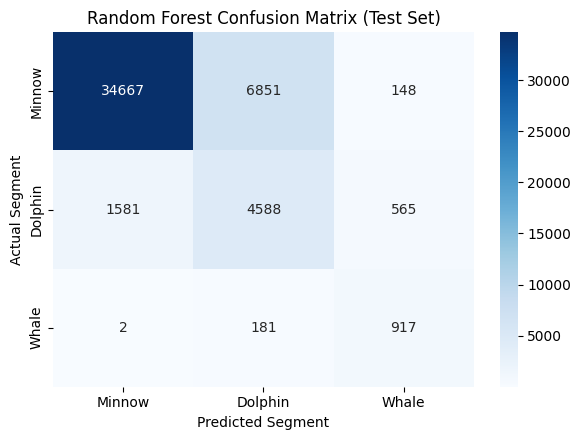

In [26]:
#Confusion matrix
cm = confusion_matrix(y_test, y_pred_tuned, labels=labels_order)
plt.figure(figsize=(6, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels_order, yticklabels=labels_order)
plt.title("Random Forest Confusion Matrix (Test Set)")
plt.xlabel("Predicted Segment")
plt.ylabel("Actual Segment")
plt.tight_layout()
plt.show()

/tmp/ipykernel_10893/2130263318.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=fi_df, x="Importance", y="Feature", palette="viridis")


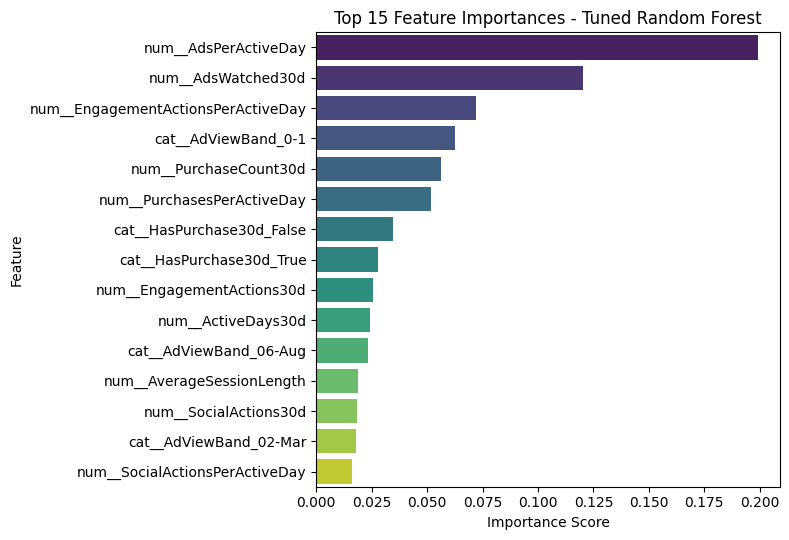

In [23]:
# 6. Visualize Feature Importance
importances = best_rf.feature_importances_
fi_df = (
    pd.DataFrame({"Feature": feature_names, "Importance": importances})
    .sort_values(by="Importance", ascending=False)
    .head(15)
)

plt.figure(figsize=(8, 5.5))
sns.barplot(data=fi_df, x="Importance", y="Feature", palette="viridis")
plt.title("Top 15 Feature Importances - Tuned Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## Model 2: NLP Classifier (Tabular-to-Text TF-IDF + Logistic Regression)

**Short Description:** This section demonstrates a tabular-to-text Natural Language Processing (NLP) approach to predict `SpendingSegment` (`Minnow`, `Dolphin`, `Whale`) using generated player profile narratives (`player_profile_text`) rather than raw player reviews.

* **Tabular-to-Text Feature Construction:** Built a vectorized `player_profile_text` column from non-leakage profile and 30-day engagement attributes (`Age`, `Gender`, `Country`, `GameGenre`, `Device`, `ActiveDays30d`, `SessionCount`, `AverageSessionLength`, `PlayerLevel30d`, `SocialActions30d`, `GuildMember`, `PushNotificationsOptIn`), excluding direct purchase and spending columns to avoid target leakage.
* **Train-Test Split & Text Vectorization:** Split `player_profile_text` and `SpendingSegment` `80/20` with `stratify=y`, then converted text into numerical features using `TfidfVectorizer(lowercase=True, ngram_range=(1, 2), max_features=5000, min_df=5)` inside a `Pipeline`.
* **Cross-Validation & Class Balancing:** Evaluated the `Pipeline` (`TfidfVectorizer` + `LogisticRegression(max_iter=500, class_weight="balanced", random_state=42)`) using 3-fold `StratifiedKFold` cross-validation (`scoring="f1_macro"`) on the training set to check consistency across folds while accounting for class imbalance across `Minnow`, `Dolphin`, and `Whale`.
* **Model Evaluation:** Trained the pipeline on the full training split and evaluated performance on the held-out test set using `Accuracy` (`0.4850`), `Balanced Accuracy` (`0.5241`), `Macro-F1` (`0.3344`), `classification_report`, and `confusion_matrix` (`Whale` recall of `0.6991`), highlighting the trade-off between text representations of generated profiles and full tabular numerical features.
* **Per-Segment Term Importance:** Extracted `LogisticRegression` coefficients (`classifier.coef_`) across classes and plotted horizontal bar charts of the top 10 terms/n-grams for `Dolphin`, `Minnow`, and `Whale` (positive vs. negative weights).

In [59]:
#1- Importing libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

In [45]:
#2-  Load cleaned dataset
df = pd.read_csv("mobile_game_players_eda_features.csv")

In [46]:
#3-  Select non-leakage profile and engagement columns plus target
required_cols = [
    "Age",
    "Gender",
    "Country",
    "GameGenre",
    "Device",
    "ActiveDays30d",
    "SessionCount",
    "AverageSessionLength",
    "PlayerLevel30d",
    "SocialActions30d",
    "GuildMember",
    "PushNotificationsOptIn",
    "SpendingSegment",
]
df_nlp = df[required_cols].dropna().copy()

In [47]:
#4-  Map boolean/yes-no fields into readable text phrases
guild_text = (
    df_nlp["GuildMember"]
    .astype(str)
    .str.strip()
    .str.lower()
    .eq("yes")
    .map({True: "is a guild member", False: "is not a guild member"})
)

notif_text = (
    df_nlp["PushNotificationsOptIn"]
    .astype(str)
    .str.strip()
    .str.lower()
    .eq("yes")
    .map({True: "opts in to push notifications", False: "does not opt in to push notifications"})
)

In [48]:
#5-  Create vectorized player profile text column (avoids row-wise apply overhead)
df_nlp["player_profile_text"] = (
    "This player is a "
    + df_nlp["Age"].astype(str)
    + "-year-old "
    + df_nlp["Gender"].astype(str).str.strip().str.lower()
    + " from "
    + df_nlp["Country"].astype(str).str.strip()
    + " playing "
    + df_nlp["GameGenre"].astype(str).str.strip()
    + " on "
    + df_nlp["Device"].astype(str).str.strip()
    + ". Over 30 days, the player recorded "
    + df_nlp["ActiveDays30d"].astype(str)
    + " active days, "
    + df_nlp["SessionCount"].astype(str)
    + " sessions with an average length of "
    + df_nlp["AverageSessionLength"].round(1).astype(str)
    + " minutes, reached level "
    + df_nlp["PlayerLevel30d"].astype(str)
    + ", and completed "
    + df_nlp["SocialActions30d"].astype(str)
    + " social actions. The player "
    + guild_text
    + " and "
    + notif_text
    + "."
)

print("Sample generated text:\n", df_nlp["player_profile_text"].iloc[0])

Sample generated text:
 This player is a 49-year-old male from Norway playing Battle Royale on Android. Over 30 days, the player recorded 5 active days, 9 sessions with an average length of 12.8 minutes, reached level 4, and completed 1 social actions. The player is not a guild member and does not opt in to push notifications.


In [49]:
#6-  Split text features and target (80/20 stratified)
X_text = df_nlp["player_profile_text"]
y = df_nlp["SpendingSegment"]

X_train, X_test, y_train, y_test = train_test_split(
    X_text,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

In [54]:
#7- Build TF-IDF + Logistic Regression pipeline with balanced class weights
nlp_pipeline = Pipeline(
    steps=[
        (
            "tfidf",
            TfidfVectorizer(
                lowercase=True,
                ngram_range=(1, 2),
                max_features=5000,
                min_df=5,
            ),
        ),
        (
            "clf",
            LogisticRegression(
                max_iter=500,
                class_weight="balanced",
                random_state=42,
            ),
        ),
    ]
)

In [60]:
#8- Run 3-fold Stratified Cross-Validation on training data only
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
cv_scores = cross_val_score(
    nlp_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1,
)

print(f"NLP 3-Fold CV Macro-F1: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")

NLP 3-Fold CV Macro-F1: 0.3318 (+/- 0.0018)


In [61]:
#9- Train and evaluate on test set
nlp_pipeline.fit(X_train, y_train)
y_pred = nlp_pipeline.predict(X_test)

labels_order = ["Minnow", "Dolphin", "Whale"]
print(f"Accuracy          : {accuracy_score(y_test, y_pred):.4f}")
print(f"Balanced Accuracy : {balanced_accuracy_score(y_test, y_pred):.4f}")
print(f"Macro-F1          : {f1_score(y_test, y_pred, average='macro'):.4f}")
print("Classification Report:", classification_report(y_test, y_pred, labels=labels_order, digits=4))

Accuracy          : 0.4850
Balanced Accuracy : 0.5241
Macro-F1          : 0.3344
Classification Report:               precision    recall  f1-score   support

      Minnow     0.8939    0.4970    0.6388     41666
     Dolphin     0.1974    0.3763    0.2590      6734
       Whale     0.0570    0.6991    0.1053      1100

    accuracy                         0.4850     49500
   macro avg     0.3828    0.5241    0.3344     49500
weighted avg     0.7806    0.4850    0.5753     49500



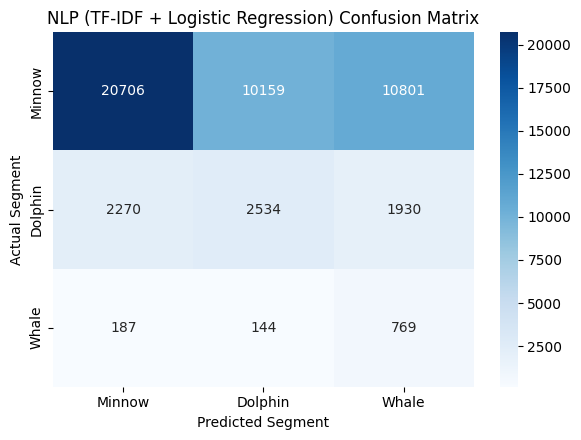

In [62]:
#10- Plot confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=labels_order)
plt.figure(figsize=(6, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels_order, yticklabels=labels_order)
plt.title("NLP (TF-IDF + Logistic Regression) Confusion Matrix")
plt.xlabel("Predicted Segment")
plt.ylabel("Actual Segment")
plt.tight_layout()
plt.show()

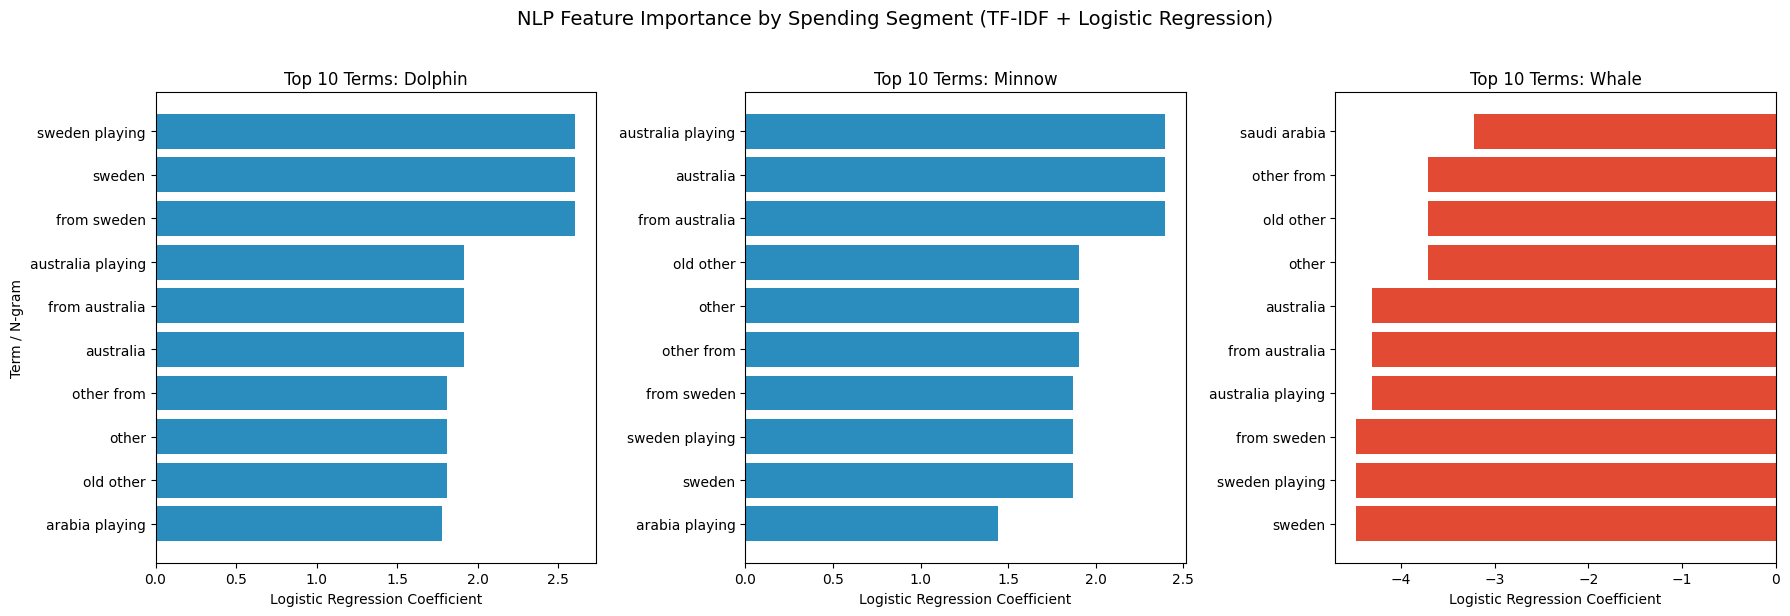

In [63]:
#11-  Extract TF-IDF vocabulary and fitted Logistic Regression classifier from the pipelinevectorizer = nlp_pipeline.named_steps["tfidf"]
classifier = nlp_pipeline.named_steps["clf"]
feature_names = np.array(vectorizer.get_feature_names_out())

# Create a 1x3 subplot layout to display top weighted terms for each spending segment
classes = classifier.classes_
fig, axes = plt.subplots(1, len(classes), figsize=(18, 6), sharex=False)

for idx, cls in enumerate(classes):
   # Get model coefficients for the current class and select the top 10 by magnitude
    coefs = classifier.coef_[idx]
    top_idx = np.argsort(np.abs(coefs))[::-1][:10]

    # Sort coefficients ascendly (highest = Top)
    sub_df = pd.DataFrame({
        "Term": feature_names[top_idx],
        "Coef": coefs[top_idx],
    }).sort_values("Coef", ascending=True)

    # Plot horizontal bars (blue for positive weight, red for negative weight)
    ax = axes[idx]
    colors = np.where(sub_df["Coef"] >= 0, "#2b8cbe", "#e34a33")
    ax.barh(sub_df["Term"], sub_df["Coef"], color=colors)

    #Title & Labels
    ax.set_title(f"Top 10 Terms: {cls}")
    ax.set_xlabel("Logistic Regression Coefficient")
    if idx == 0:
        ax.set_ylabel("Term / N-gram")

# Add overall figure title, adjust layout, save chart, and render output
plt.suptitle("NLP Feature Importance by Spending Segment (TF-IDF + Logistic Regression)", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig("nlp_feature_importance_per_group.png", dpi=150, bbox_inches="tight")
plt.show()